<a href="https://colab.research.google.com/github/Zheleikina/ML/blob/main/%D0%9B%D0%A06_%D0%96%D0%B5%D0%BB%D0%B5%D0%B9%D0%BA%D1%96%D0%BD%D0%B0_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 5 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [2]:
# Завантаження файлу
uploaded = files.upload()

In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [4]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


- **gender** — стать (чоловіча або жіноча).
- **age** — вік людини.
- **hypertension** — наявність гіпертонії (0 — ні, 1 — так).
- **heart_disease** — наявність серцевих захворювань (0 — ні, 1 — так).
- **smoking_history** — історія куріння (ніколи, раніше, зараз або немає інформації).
- **bmi** — індекс маси тіла.
- **HbA1c_level** — рівень глікованого гемоглобіну.
- **blood_glucose_level** — рівень глюкози в крові.
- **diabetes** — наявність діабету (0 — ні, 1 — так).

Вивести інформацію про датасет

In [5]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [6]:
# TODO: підрахуйте частоти категорій у gender.

df["gender"].value_counts()

,count
gender,
Female,58552
Male,41430
Other,18


In [7]:
df["gender"].value_counts(normalize=True) * 100

,proportion
gender,
Female,58.552
Male,41.430
Other,0.018


In [8]:
# TODO: підрахуйте частоти категорій у smoking_history.

df["smoking_history"].value_counts()

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [9]:
# TODO: df

df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [10]:
# TODO: df.dtypes

df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [11]:
# TODO: df['diabetes'].value_counts()

df["diabetes"].value_counts()

,count
diabetes,
0,91500
1,8500


**Висновок:** визначте за результатом, чи є дисбаланс класів.

у датасеті спостерігається значний дисбаланс класів. Клас 0 (відсутність діабету) містить 91 500 записів (91,5%), а клас 1 (наявність діабету) — 8 500 записів (8,5%). Отже, кількість записів класу 0 приблизно у 10,8 раза більша, ніж класу 1.

Перевірити наявність пропущених даних


In [12]:
# TODO: df.isnull().sum()

df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [13]:
# TODO: df.duplicated().sum()

df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [14]:
# TODO: df.drop_duplicates(inplace=True)

df.drop_duplicates(inplace=True)

In [15]:
# TODO: df

df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


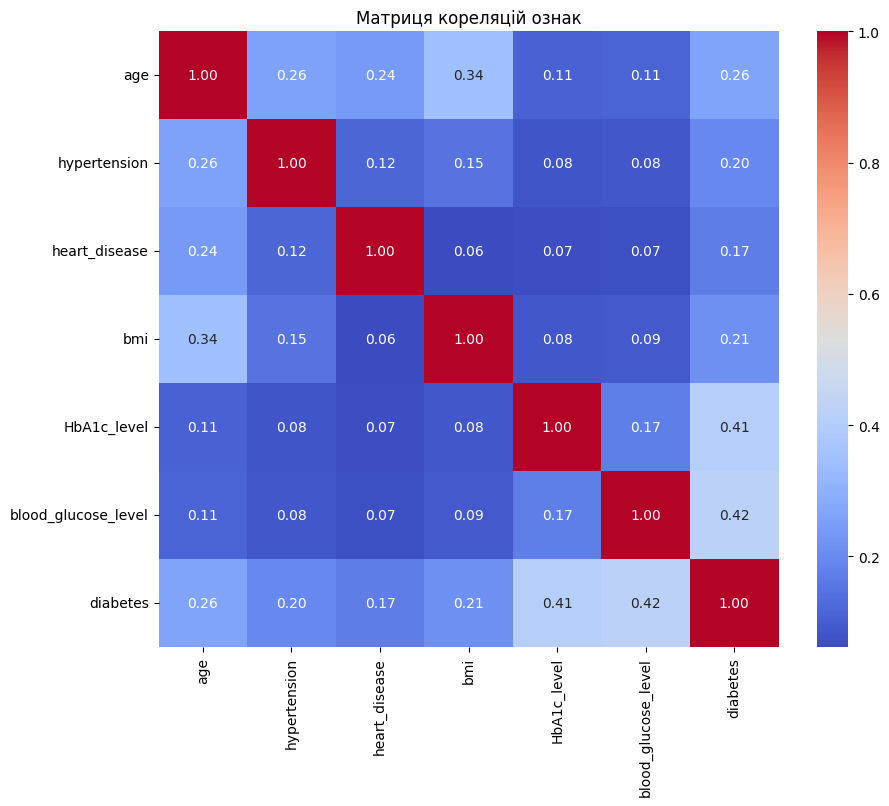

In [38]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Матриця кореляцій ознак")
plt.show()

Ще раз перевірити баланс цільової змінної

In [16]:
# TODO: df['diabetes'].value_counts()

df["diabetes"].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

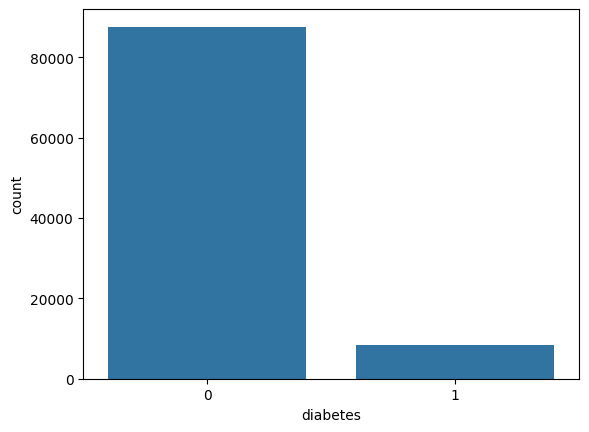

In [17]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')

sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [18]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [19]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.

# Створення X та y
X = df.drop(columns=["diabetes"])
y = df["diabetes"]

# Поділ на навчальну та тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Описові статистики навчальної вибірки
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [20]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).

# Кодування категоріальних ознак після поділу
X_train = pd.get_dummies(
    X_train,
    columns=["gender", "smoking_history"],
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=["gender", "smoking_history"],
    dtype=int
)

# Вирівнювання стовпців тестової вибірки за навчальною
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Перевірка результату
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print(X_train.head())

X_train: (76916, 15)
X_test: (19230, 15)
        age  hypertension  heart_disease    bmi  HbA1c_level  \
79000  45.0             0              0  23.87          5.7   
32011  64.0             0              0  33.03          4.0   
95559  45.0             0              0  27.32          6.6   
32057  44.0             1              0  28.86          4.8   
97797  27.0             0              0  26.48          6.5   

       blood_glucose_level  gender_Female  gender_Male  gender_Other  \
79000                  126              0            1             0   
32011                  126              1            0             0   
95559                  126              1            0             0   
32057                   80              0            1             0   
97797                  200              1            0             0   

       smoking_history_No Info  smoking_history_current  smoking_history_ever  \
79000                        1                        0     

In [21]:
# TODO: виведіть статистики опису X_train.

X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.582675,0.417143,0.000182,0.342022,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493121,0.493090,0.013490,0.474390,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [22]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).

correlations = X_train.corrwith(y_train).sort_values(ascending=False)

print(correlations)

blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_former         0.096162
gender_Male                    0.040650
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
gender_Female                 -0.040533
smoking_history_No Info       -0.113053
dtype: float64


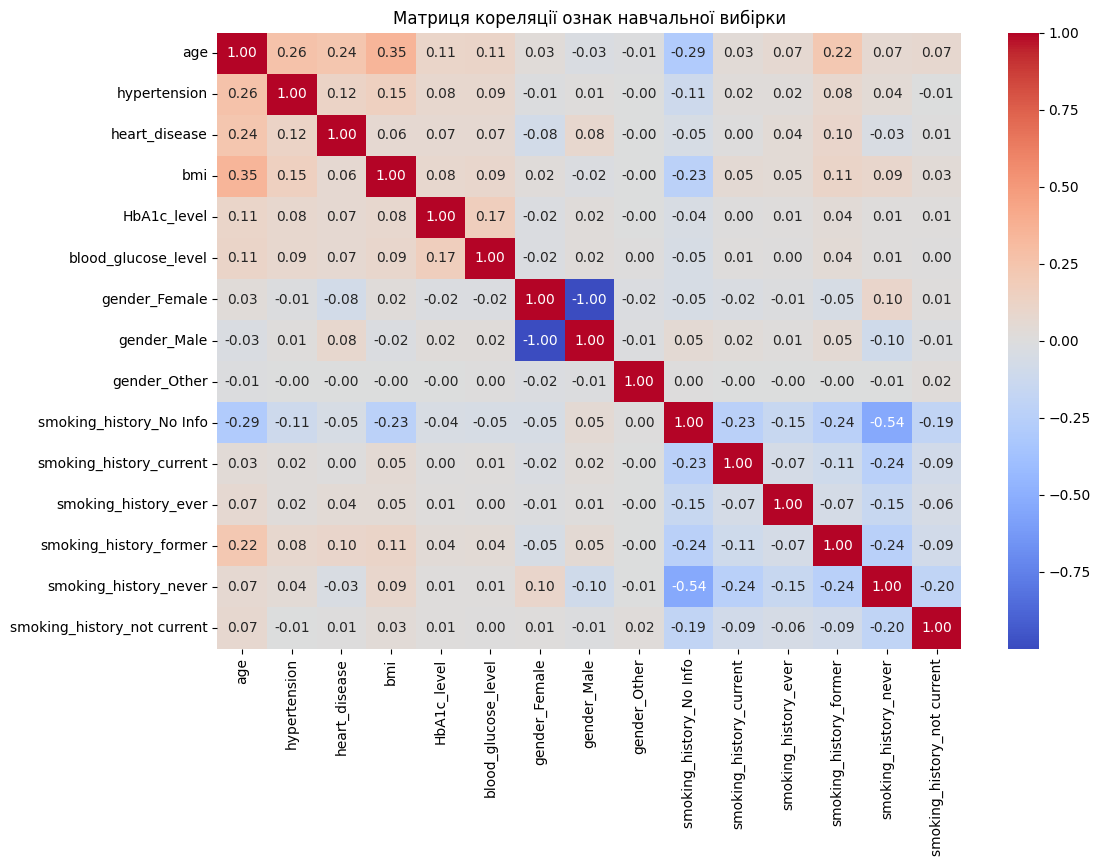

In [23]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).

corr_matrix = X_train.corr()

# Побудова теплової карти
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Матриця кореляції ознак навчальної вибірки")
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Найбільшу кореляцію з цільовою змінною diabetes мають blood_glucose_level (0,423) та HbA1c_level (0,405), дещо меншу — age (0,267) і bmi (0,213). Інші ознаки мають слабший лінійний зв’язок із цільовою змінною. Видаляти ознаки поки не потрібно.

Перевірити викиди **лише на навчальній вибірці**

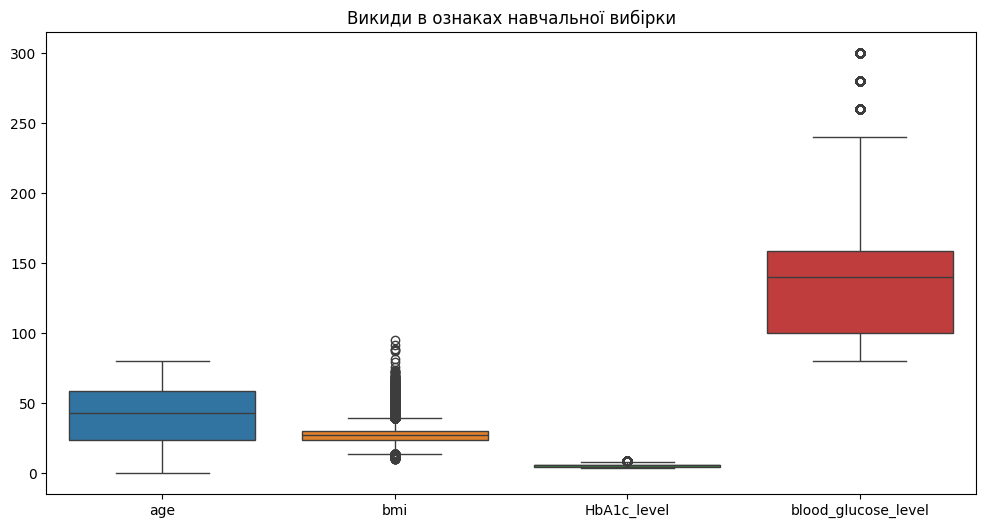

In [24]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.

continuous_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]

plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title("Викиди в ознаках навчальної вибірки")
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [25]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

# Для bmi обчислюємо Q1 і Q3 лише на X_train.
# IQR = Q3 - Q1.
# Межі викидів: Q1 - 1.5 * IQR та Q3 + 1.5 * IQR.
# У цій роботі викиди не видаляємо.

Перевірити асиметрію розподілів ознак **на train**

In [26]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].

skewness = X_train[continuous_cols].skew()
print(skewness)

age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
dtype: float64


In [27]:
# TODO: перевірте пропуски окремо в X_train та X_test.

print("Пропуски в X_train:")
print(X_train.isnull().sum())

print("\nПропуски в X_test:")
print(X_test.isnull().sum())

Пропуски в X_train:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64

Пропуски в X_test:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never  

**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

У навчальній вибірці переважає клас 0, тому класи незбалансовані. Найбільшу кореляцію з цільовою ознакою мають рівень глюкози в крові та рівень HbA1c. Ознаки bmi і blood_glucose_level мають додатну асиметрію, також у даних можуть бути викиди. Викиди не видаляємо, а тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [28]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [29]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.

smote = SMOTE(random_state=42)

print("Кількість класів до балансування:")
print(y_train.value_counts())

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled, y_train
)

print("\nКількість класів після балансування:")
print(y_train_balanced.value_counts())

Кількість класів до балансування:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Кількість класів після балансування:
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [30]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.

models = {
    "LogisticRegression": LogisticRegression(random_state=42),
    "RidgeClassifier": RidgeClassifier(),
    "SGDClassifier": SGDClassifier(random_state=42),
    "SVC": SVC()
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Модель: LogisticRegression
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



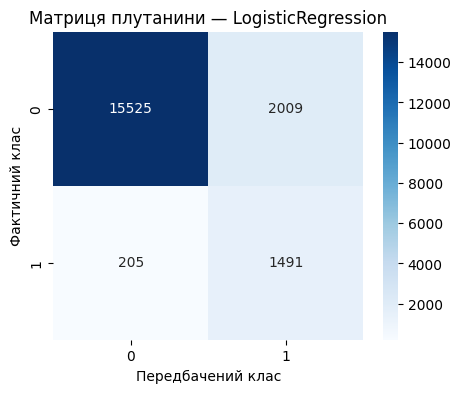


Модель: RidgeClassifier
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



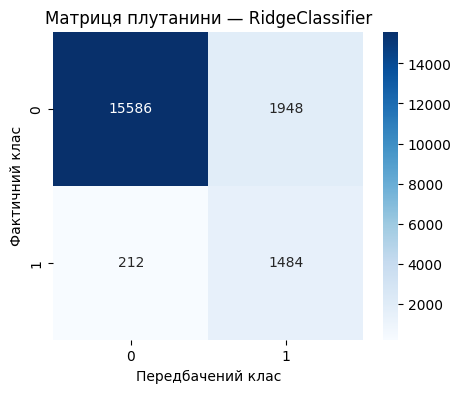


Модель: SGDClassifier
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



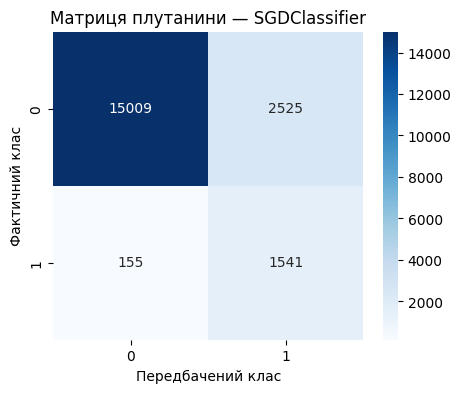


Модель: SVC
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



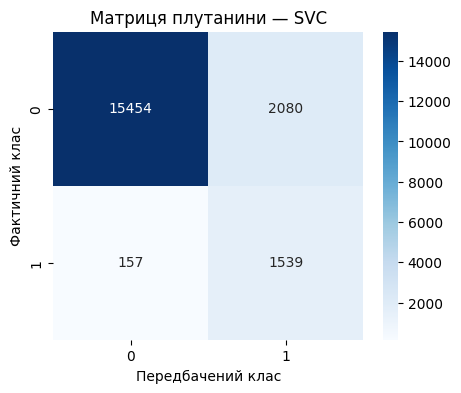

In [31]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).

for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)
    y_pred = model.predict(X_test_scaled)

    print(f"\nМодель: {name}")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Матриця плутанини — {name}")
    plt.xlabel("Передбачений клас")
    plt.ylabel("Фактичний клас")
    plt.show()

Оптимізувати гіперпараметри


In [32]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.

param_grids = {
    "LogisticRegression": {
        "C": [0.1, 1, 10],
        "solver": ["liblinear", "lbfgs"]
    },
    "RidgeClassifier": {
        "alpha": [0.1, 1, 10]
    },
    "SGDClassifier": {
        "loss": ["hinge", "log_loss"],
        "penalty": ["l2", "l1"],
        "alpha": [0.0001, 0.001, 0.01]
    },
    "SVC": {
        "C": [0.1, 1, 10],
        "kernel": ["linear", "rbf"]
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [33]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline


Модель: LogisticRegression
Найкращі параметри: {'classifier__C': 1, 'classifier__solver': 'lbfgs'}
Найкращий F1: 0.6254
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



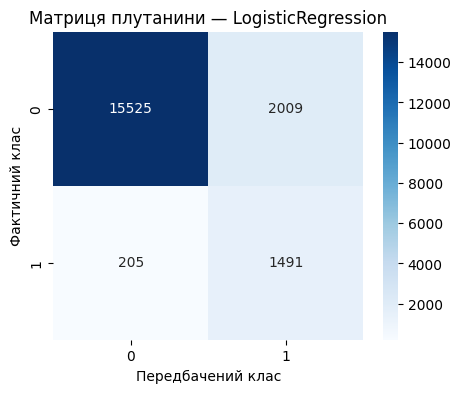


Модель: RidgeClassifier
Найкращі параметри: {'classifier__alpha': 10}
Найкращий F1: 0.5601
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



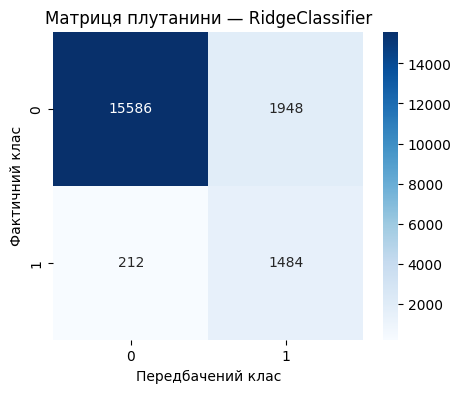


Модель: SGDClassifier
Найкращі параметри: {'classifier__alpha': 0.0001, 'classifier__loss': 'log_loss', 'classifier__penalty': 'l1'}
Найкращий F1: 0.6133
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



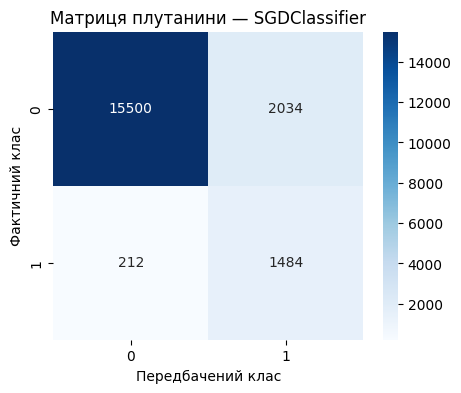


Модель: SVC
Найкращі параметри: {'classifier__C': 1, 'classifier__kernel': 'linear'}
Найкращий F1: 0.6042
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.89      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



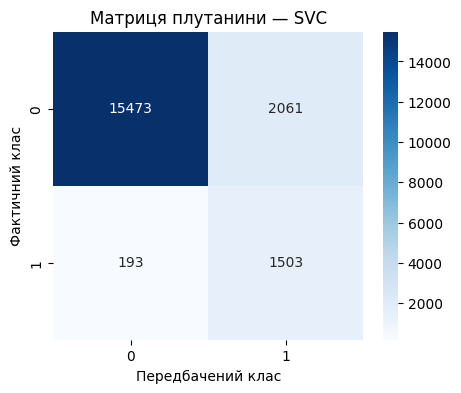

In [37]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.

best_models = {}
best_scores = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("classifier", model)
    ])

    grid = {
        f"classifier__{key}": value
        for key, value in param_grids[name].items()
    }

    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=grid,
        cv=3,
        scoring="f1",
        min_resources=300,
        factor=3,
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print(f"\nМодель: {name}")
    print("Найкращі параметри:", search.best_params_)
    print("Найкращий F1:", round(search.best_score_, 4))

    y_pred = search.best_estimator_.predict(X_test)
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Матриця плутанини — {name}")
    plt.xlabel("Передбачений клас")
    plt.ylabel("Фактичний клас")
    plt.show()

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [35]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.

best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]

print("Найкраща модель:", best_name)
print("Середній F1 на кросвалідації:", round(best_scores[best_name], 4))

Найкраща модель: SVC
Середній F1 на кросвалідації: 0.6579


In [36]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.

random_indices = X_test.sample(n=10, random_state=42).index

y_pred = best_model.predict(X_test.loc[random_indices])

comparison = pd.DataFrame({
    "Індекс": random_indices,
    "Істинний клас": y_test.loc[random_indices].values,
    "Передбачений клас": y_pred
})

print(comparison.to_string(index=False))

 Індекс  Істинний клас  Передбачений клас
  36061              0                  0
  29824              0                  0
  29668              0                  1
  11816              0                  0
  99242              0                  0
  26718              0                  0
  53059              0                  0
  69294              0                  0
   8912              0                  1
  37072              0                  0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

**Висновок:**

1. Спостерігався дисбаланс класів: 91,5% — клас 0, 8,5% — клас 1. Найбільшу кореляцію з діабетом мали рівень глюкози та HbA1c. На train виявлено асиметрію bmi і blood_glucose_level та можливі викиди.

2. Найкращий F1 за кросвалідацією отримала SVC — 0,6579. Recall для класу 1 становив 0,89.

3. Для SVC оптимальні параметри: C = 1, kernel = linear. Основні помилки — хибне визначення діабету в людей без нього та пропуск окремих випадків діабету.

4. Розділення даних запобігає витоку інформації. Масштабування та SMOTE застосовують лише до train, щоб тестування об’єктивно оцінювало якість моделі.